# Кейс 2. Прогнозирование оттока абонентов телеком-оператора

**Цель:** предсказать вероятность ухода абонента (`Отток`) и выделить ключевые факторы риска.
**Данные:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — подгружаются автоматически по ссылке на зеркало файла.

**План:** 1) загрузка и оптимизация типов → 2) EDA → 3) подготовка признаков → 4) базовые модели → 5) факторы риска → 6) выводы.

## 0. Установка и импорт библиотек

In [1]:
# Раскомментируйте в чистой среде (Colab и т.п.)
# !pip install -q pandas scikit-learn matplotlib seaborn phik

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik  # нужен для df.phik_matrix()

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42   # фиксируем, чтобы результаты воспроизводились
sns.set_theme(style="whitegrid")

## 1. Загрузка данных (автоматически, по ссылке)

In [3]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Описание датасета (оригинал с Kaggle)
Источник: [Telco Customer Churn, blastchar](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM Sample Data Sets).

> **Context.** Predict behavior to retain customers. You can analyze all relevant customer data and develop focused customer retention programs.
>
> **Content.** Each row represents a customer, each column contains customer's attributes described on the column Metadata.
>
> The data set includes information about:
> - Customers who left within the last month – the column is called Churn
> - Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
> - Customer account information – how long they've been a customer, contract, payment method, paperless billing, monthly charges, and total charges
> - Demographic info about customers – gender, age range, and if they have partners and dependents
>
> **Inspiration.** To explore this type of models and learn more about the subject.

*Перевод:* каждая строка — клиент, каждый столбец — его атрибут. В данных есть: клиенты, ушедшие в течение последнего месяца (столбец `Churn`); подключённые услуги; информация об аккаунте (срок жизни, контракт, способ оплаты, электронный счёт, ежемесячные и суммарные платежи); демография (пол, возрастная группа, наличие партнёра и иждивенцев).

### Расшифровка столбцов
Признаки (оригинальное название → русское название в ноутбуке):

| Группа | Оригинал | Русское название | Что означает |
|---|---|---|---|
| Профиль | `gender` | Пол | Женский / Мужской |
| | `SeniorCitizen` | Пенсионер | 1 — пожилой клиент |
| | `Partner` | Есть партнёр | Состоит ли в паре |
| | `Dependents` | Есть иждивенцы | Есть ли дети/иждивенцы |
| Услуги | `PhoneService` | Телефония | Подключена ли телефонная связь |
| | `MultipleLines` | Несколько линий | Больше одной телефонной линии |
| | `InternetService` | Интернет | Тип: DSL / Оптоволокно / нет |
| | `OnlineSecurity` | Онлайн-защита | Антивирус/защита в сети |
| | `OnlineBackup` | Облачный бэкап | Резервное копирование в облаке |
| | `DeviceProtection` | Защита устройства | Страховка оборудования |
| | `TechSupport` | Техподдержка | Подключена ли техподдержка |
| | `StreamingTV` | Стриминг ТВ | Онлайн-ТВ |
| | `StreamingMovies` | Стриминг кино | Онлайн-кинотеатр |
| Контракт | `Contract` | Контракт | Помесячный / Годовой / Двухлетний |
| | `PaperlessBilling` | Электронный счёт | Счёт без бумаги |
| | `PaymentMethod` | Способ оплаты | Электронный чек, чек по почте, банковский перевод, карта |
| Платежи | `tenure` | Стаж | Сколько месяцев клиент с оператором |
| | `MonthlyCharges` | Платёж в месяц | Текущий ежемесячный платёж |
| | `TotalCharges` | Всего оплачено | Сумма платежей за всё время |
| **Цель** | `Churn` | **Отток** | 1 — клиент ушёл, 0 — остался |

`customerID` (идентификатор) не используем.

### Очистка, перевод и оптимизация типов
- `TotalCharges` читается как строка: у новых абонентов (tenure = 0) там пробел → превращаем в число, пропуск заполняем 0 (они ещё ничего не платили).
- Целевую переменную переводим в 0/1.
- **Переводим названия столбцов и значения на русский**, чтобы все таблицы и графики ниже были на русском.
- Строки → `category`, числа → `float32`/`int8` (экономия памяти).

In [4]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2

# --- переводы (словари: оригинал -> русский) ---
COLS_RU = {
    "gender": "Пол", "SeniorCitizen": "Пенсионер", "Partner": "Есть партнёр",
    "Dependents": "Есть иждивенцы", "tenure": "Стаж", "PhoneService": "Телефония",
    "MultipleLines": "Несколько линий", "InternetService": "Интернет",
    "OnlineSecurity": "Онлайн-защита", "OnlineBackup": "Облачный бэкап",
    "DeviceProtection": "Защита устройства", "TechSupport": "Техподдержка",
    "StreamingTV": "Стриминг ТВ", "StreamingMovies": "Стриминг кино",
    "Contract": "Контракт", "PaperlessBilling": "Электронный счёт",
    "PaymentMethod": "Способ оплаты", "MonthlyCharges": "Платёж в месяц",
    "TotalCharges": "Всего оплачено", "Churn": "Отток",
}
VALUES_RU = {
    "Yes": "Да", "No": "Нет",
    "No internet service": "Нет интернета", "No phone service": "Нет телефонии",
    "Female": "Женский", "Male": "Мужской",
    "Fiber optic": "Оптоволокно",
    "Month-to-month": "Помесячный", "One year": "Годовой", "Two year": "Двухлетний",
    "Electronic check": "Электронный чек", "Mailed check": "Чек по почте",
    "Bank transfer (automatic)": "Банковский перевод (авто)",
    "Credit card (automatic)": "Кредитная карта (авто)",
}

df = df.drop(columns="customerID")                                  # ID не несёт информации
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype("int8")                 # 1 = ушёл
df["SeniorCitizen"] = df["SeniorCitizen"].astype("int8")            # 0/1

df = df.rename(columns=COLS_RU)                                     # названия столбцов -> русский
text_cols = df.select_dtypes(exclude="number").columns.tolist()
for col in text_cols:                                               # значения -> русский
    df[col] = df[col].replace(VALUES_RU).astype("category")

df["Стаж"] = df["Стаж"].astype("int8")
df[["Платёж в месяц", "Всего оплачено"]] = df[["Платёж в месяц", "Всего оплачено"]].astype("float32")

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"Память: {mem_before:.2f} МБ → {mem_after:.2f} МБ")
df.info()

Память: 6.82 МБ → 0.18 МБ
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Пол                7043 non-null   category
 1   Пенсионер          7043 non-null   int8    
 2   Есть партнёр       7043 non-null   category
 3   Есть иждивенцы     7043 non-null   category
 4   Стаж               7043 non-null   int8    
 5   Телефония          7043 non-null   category
 6   Несколько линий    7043 non-null   category
 7   Интернет           7043 non-null   category
 8   Онлайн-защита      7043 non-null   category
 9   Облачный бэкап     7043 non-null   category
 10  Защита устройства  7043 non-null   category
 11  Техподдержка       7043 non-null   category
 12  Стриминг ТВ        7043 non-null   category
 13  Стриминг кино      7043 non-null   category
 14  Контракт           7043 non-null   category
 15  Электронный счёт   7043 non-null   categ

## 2. Первичный анализ данных (EDA)

In [5]:
print("Пропуски:", df.isna().sum().sum(), "| Дубликаты строк:", df.duplicated().sum())
df.describe().T

Пропуски: 0 | Дубликаты строк: 22


,count,mean,std,min,25%,50%,75%,max
Пенсионер,7043.0,0.162147,0.368612,0.00,0.000000,0.000000,0.000000,1.000000
Стаж,7043.0,32.371149,24.559481,0.00,9.000000,29.000000,55.000000,72.000000
Платёж в месяц,7043.0,64.761696,30.090048,18.25,35.500000,70.349998,89.849998,118.750000
Всего оплачено,7043.0,2279.734375,2266.794434,0.00,398.549988,1394.550049,3786.599976,8684.799805
Отток,7043.0,0.265370,0.441561,0.00,0.000000,0.000000,1.000000,1.000000


**Баланс классов.** Уходит около четверти абонентов — классы несбалансированы, поэтому одной accuracy мало, смотрим ROC-AUC, recall и F1.

Отток
0    0.735
1    0.265
Name: proportion, dtype: float64


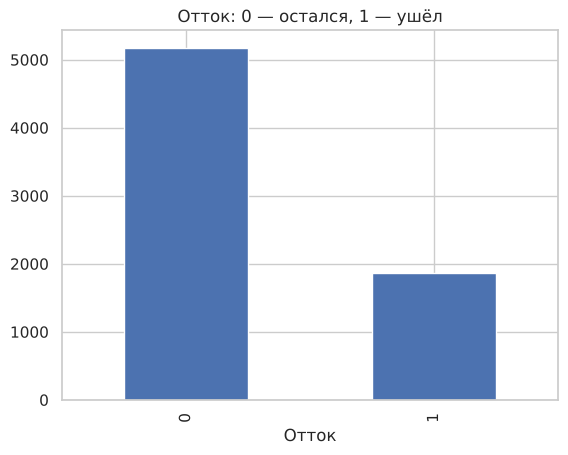

In [6]:
print(df["Отток"].value_counts(normalize=True).round(3))
df["Отток"].value_counts().plot.bar(title="Отток: 0 — остался, 1 — ушёл");

**Числовые признаки и отток.** Уходят чаще новички (малый Стаж) и те, у кого высокий ежемесячный платёж.

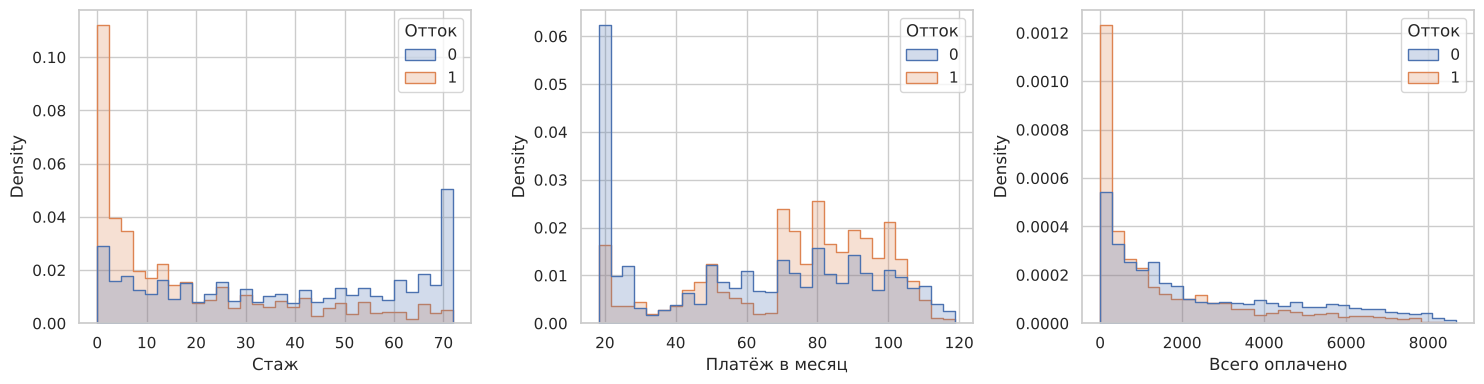

In [7]:
num_cols = ["Стаж", "Платёж в месяц", "Всего оплачено"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Отток", bins=30, element="step", stat="density", common_norm=False, ax=ax)
plt.tight_layout()

**Категориальные признаки.** Доля ушедших внутри каждой категории (для ключевых признаков).

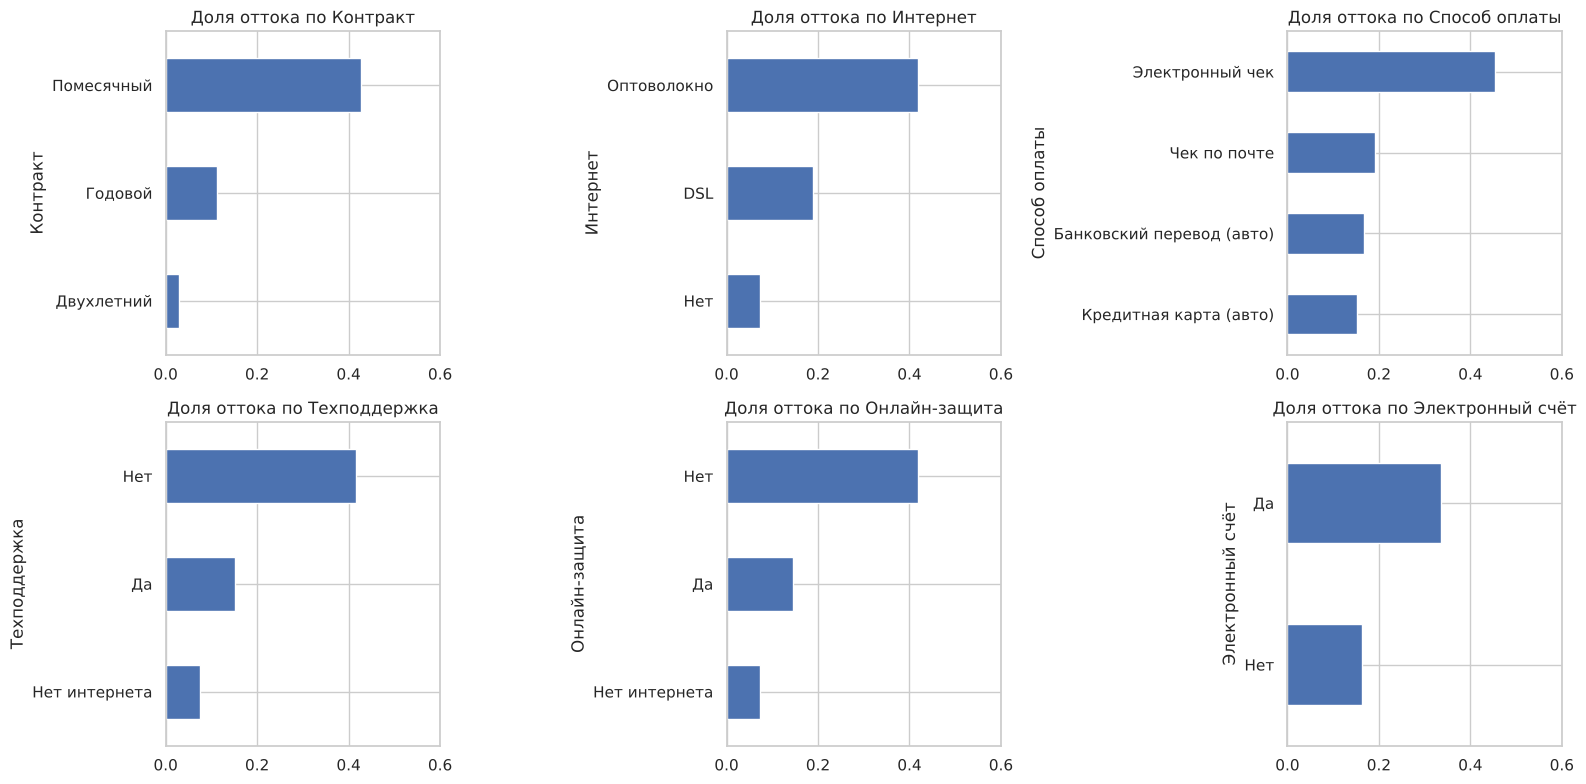

In [8]:
key_cols = ["Контракт", "Интернет", "Способ оплаты", "Техподдержка", "Онлайн-защита", "Электронный счёт"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_cols):
    rate = df.groupby(col, observed=True)["Отток"].mean().sort_values()
    rate.plot.barh(ax=ax, title=f"Доля оттока по {col}")
    ax.set_xlim(0, 0.6)
plt.tight_layout()

**Корреляции — коэффициент Фиката (Phik).** В отличие от Пирсона работает и с категориями, и с нелинейными связями.
Смотрим, какие признаки сильнее всего связаны с `Отток`.

In [9]:
interval = ["Стаж", "Платёж в месяц", "Всего оплачено"]
phik_corr = df.phik_matrix(interval_cols=interval)
phik_corr["Отток"].drop("Отток").sort_values(ascending=False).to_frame("Phik с оттоком")

,Phik с оттоком
Стаж,0.474001
Способ оплаты,0.449125
Платёж в месяц,0.360021
Электронный счёт,0.295754
Всего оплачено,0.278498
Есть иждивенцы,0.253936
Контракт,0.251639
Пенсионер,0.233432
Есть партнёр,0.232930
Онлайн-защита,0.211840


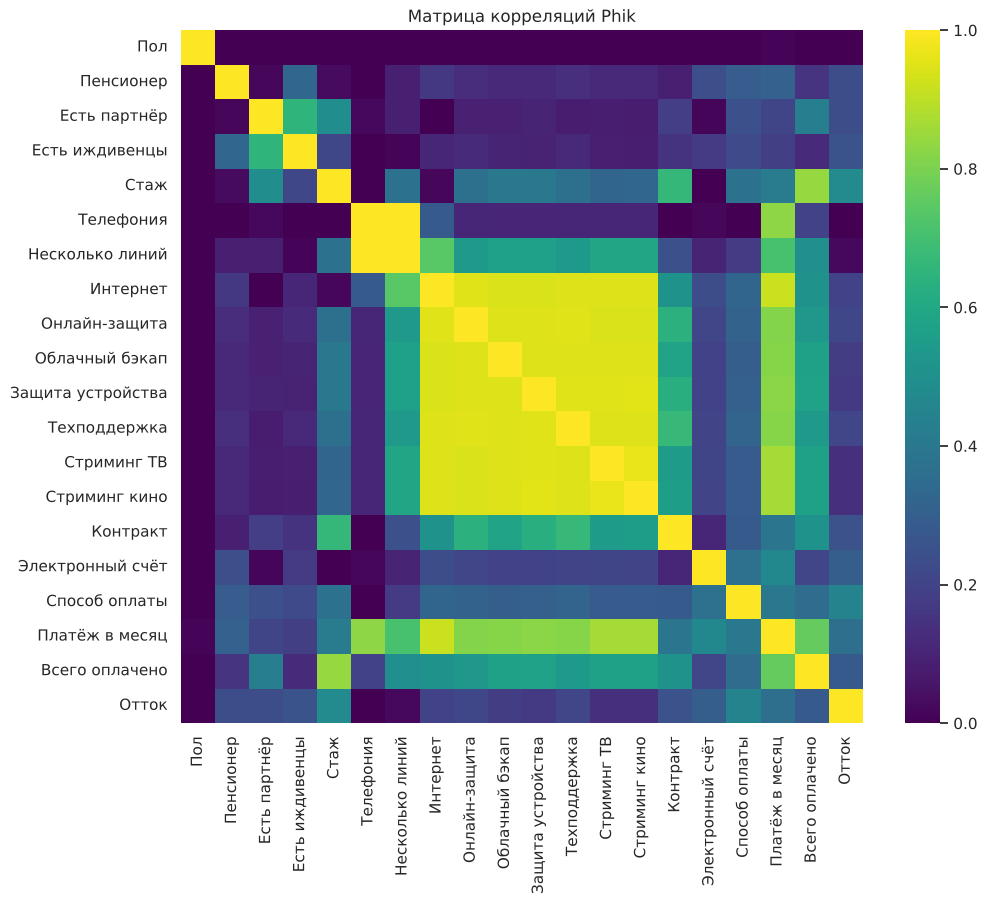

In [10]:
plt.figure(figsize=(11, 9))
sns.heatmap(phik_corr, cmap="viridis", vmin=0, vmax=1)
plt.title("Матрица корреляций Phik");

> **Выводы EDA:** по Phik сильнее всего с оттоком связаны `Стаж`, `Способ оплаты` и `Платёж в месяц`; заметна связь и с `Контракт`, `Электронный счёт`.
> `Пол` и `Телефония` не связаны с оттоком вообще. `Всего оплачено` сильно зависит от `Стаж` (≈ Стаж × Платёж в месяц).
> Phik показывает силу связи, но не направление — направление смотрим на графиках выше и в коэффициентах модели (раздел 5).

> Автоотчёт (по желанию): `from ydata_profiling import ProfileReport; ProfileReport(df).to_notebook_iframe()`

## 3. Подготовка признаков
Делим на train/test (с `stratify`, чтобы доля оттока была одинаковой), затем в одном `Pipeline`:
- числа → `StandardScaler`,
- категории → `OneHotEncoder`.

Преобразования внутри пайплайна учатся только на train → нет утечки данных.

In [11]:
X = df.drop(columns="Отток")
y = df["Отток"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_features = X.select_dtypes("number").columns.tolist()
cat_features = X.select_dtypes("category").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_features),
])
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5634, 19) | Test: (1409, 19)


## 4. Базовые модели
Две простые и объяснимые модели:
1. **Логистическая регрессия** — линейная, коэффициенты легко читаются.
2. **Случайный лес** — нелинейная, ловит взаимодействия признаков.

`class_weight="balanced"` компенсирует дисбаланс классов.

In [12]:
models = {
    "Логистическая регрессия": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Случайный лес": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_depth=8,
                                           class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}

fitted, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({"Модель": name,
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "Точность (Precision)": precision_score(y_test, pred),
                 "Полнота (Recall)": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Модель").round(3)
results

,ROC-AUC,Точность (Precision),Полнота (Recall),F1
Модель,,,,
Логистическая регрессия,0.842,0.504,0.783,0.614
Случайный лес,0.843,0.519,0.791,0.627


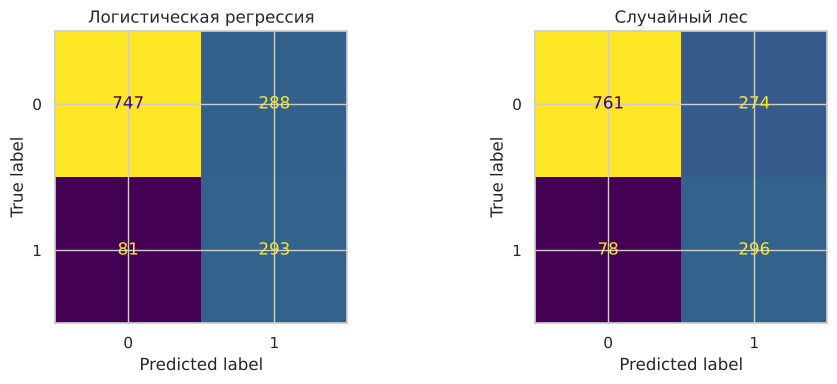

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()

Обе модели дают близкое качество (ROC-AUC ≈ 0.84) — для такого набора это типичный результат; простая логрегрессия не хуже леса, поэтому её можно использовать как основную из-за интерпретируемости.

## 5. Ключевые факторы риска ухода
### 5.1 Коэффициенты логистической регрессии
Положительный коэффициент → признак **повышает** вероятность оттока, отрицательный → **снижает**.
(Числа стандартизованы, поэтому их коэффициенты можно сравнивать между собой.)

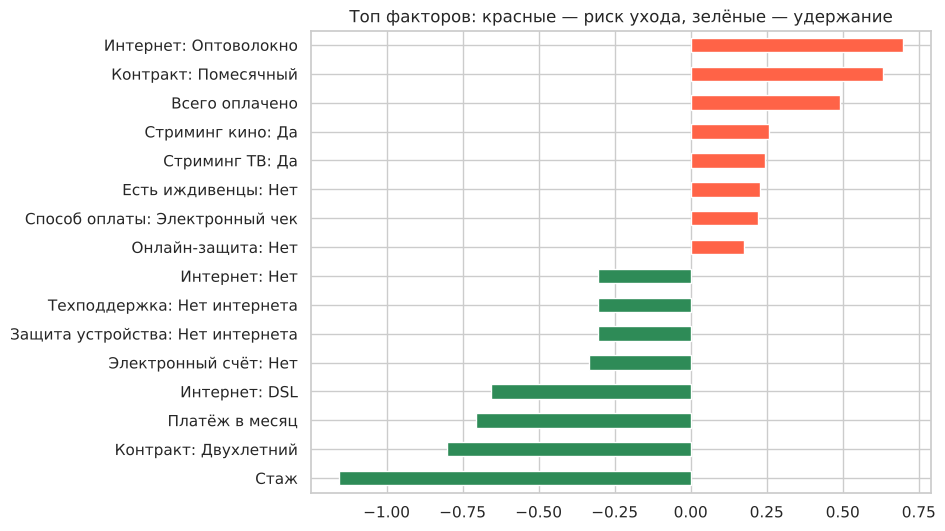

In [14]:
lr = fitted["Логистическая регрессия"]
names = lr.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1].replace("_", ": ", 1) for n in names]   # убираем служебный префикс
coef = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()

top = pd.concat([coef.head(8), coef.tail(8)])
top.plot.barh(figsize=(8, 6), color=(top > 0).map({True: "tomato", False: "seagreen"}),
              title="Топ факторов: красные — риск ухода, зелёные — удержание");

### 5.2 Permutation importance (для случайного леса)
Перемешиваем один исходный признак и смотрим, насколько падает ROC-AUC на тесте. Чем больше падение — тем важнее признак.

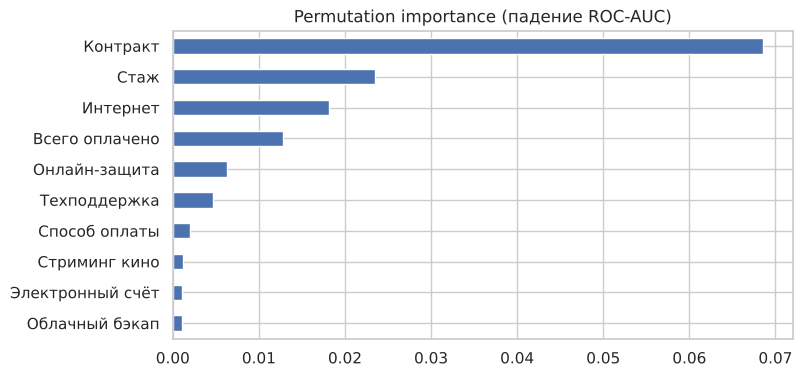

In [15]:
perm = permutation_importance(fitted["Случайный лес"], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.tail(10).plot.barh(figsize=(8, 4), title="Permutation importance (падение ROC-AUC)");

## 6. Выводы
**Качество:** ROC-AUC ≈ 0.84 на отложенной выборке; recall по классу «отток» ≈ 0.78 за счёт `class_weight="balanced"` (ценой более низкой precision).

**Факторы риска ухода:**
1. **Контракт «месяц в месяц»** — главный фактор; годовые и двухлетние контракты резко снижают отток.
2. **Малый срок обслуживания (Стаж)** — первые месяцы самые рискованные.
3. **Оптоволоконный интернет** — у DSL-абонентов отток ниже.
4. **Безбумажный биллинг** и рост суммарных платежей (`Всего оплачено`) при прочих равных.
5. **Отсутствие доп. услуг** («Техподдержка», «Онлайн-защита») — по важности признаков они заметны, клиенты с ними уходят реже.

*Примечание:* `Платёж в месяц` в линейной модели получает отрицательный коэффициент — он сильно коррелирует с типом интернета и допуслугами, поэтому в одиночку его читать нельзя (на графиках EDA высокий платёж связан с оттоком).

**Рекомендации бизнесу:** переводить клиентов на длинные контракты, давать бонусы новичкам в первые месяцы, предлагать пакет «Техподдержка»/«Онлайн-защита», проверить качество и цену оптоволоконных тарифов.

**Дальше (к итоговой защите):** подбор гиперпараметров (`GridSearchCV`), градиентный бустинг, подбор порога классификации под бизнес-метрику, SHAP.